EDA Data Preparation

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from datasets import load_dataset

ds = load_dataset(
    "Rajarshi-Roy-research/Defactify_Image_Dataset",
    cache_dir="/content/drive/MyDrive/dataset_huggingface"
)

README.md:   0%|          | 0.00/5.37k [00:00<?, ?B/s]

data/validation-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  333MB            

data/validation-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/validation-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  345MB            

data/validation-00001-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00000-of-00007.parquet: reconstructing file:   0%|          |  0.00B /  448MB            

... (28 outputs left out)

data/test-00007-of-00008.parquet: downloading bytes:           |  0.00B            

Generating validation split:   0%|          | 0/9000 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/42000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/45000 [00:00<?, ? examples/s]

In [3]:
# Task 1: Loading & Inspection Dataset

# 1. Cek struktur umum dataset
print("=== STRUKTUR DATASET ===")
print(ds)

# 2. Cek fitur/kolom yang tersedia di split 'train'
print("\n=== KOLOM / FITUR ===")
print(ds['train'].features)

# 3. Cek sampel data pertama
print("\n=== CONTOH DATA PERTAMA (TRAIN) ===")
sample = ds['train'][0]
for key, value in sample.items():
    if key != 'image':  # Jangan cetak mentahan objek gambar agar output rapi
        print(f"{key}: {value}")
    else:
        print(f"{key}: {type(value)} (Resolusi: {value.size}, Mode: {value.mode})")

=== STRUKTUR DATASET ===
DatasetDict({
    validation: Dataset({
        features: ['Caption', 'Image', 'Label_A', 'Label_B'],
        num_rows: 9000
    })
    train: Dataset({
        features: ['Caption', 'Image', 'Label_A', 'Label_B'],
        num_rows: 42000
    })
    test: Dataset({
        features: ['Caption', 'Image', 'Label_A', 'Label_B'],
        num_rows: 45000
    })
})

=== KOLOM / FITUR ===
{'Caption': Value('string'), 'Image': Image(mode=None, decode=True), 'Label_A': Value('int32'), 'Label_B': Value('int32')}

=== CONTOH DATA PERTAMA (TRAIN) ===
Caption: Two tall giraffe standing next to each other on a  field.
Image: <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=640x480 at 0x7C6DE0E27CB0>
Label_A: 0
Label_B: 0


In [4]:
import pandas as pd

# --- TASK 2: Memahami Struktur Kolom Dataset ---
print("=== TASK 2: STRUKTUR KOLOM ===")
fitur_dataset = ds['train'].features
for nama_kolom, tipe_data in fitur_dataset.items():
    print(f"Kolom '{nama_kolom}' -> Tipe Data: {tipe_data}")

print("\n")

# --- TASK 3: Menghitung Jumlah Keseluruhan Gambar ---
print("=== TASK 3: REKAP JUMLAH GAMBAR ===")
jumlah_train = ds['train'].num_rows
jumlah_val = ds['validation'].num_rows
jumlah_test = ds['test'].num_rows
total_keseluruhan = jumlah_train + jumlah_val + jumlah_test

# Membungkus hasil ke dalam Pandas DataFrame agar tabelnya tampil rapi di Colab
df_rekap = pd.DataFrame({
    'Bagian (Split)': ['Train', 'Validation', 'Test', 'Total Keseluruhan'],
    'Jumlah Gambar': [jumlah_train, jumlah_val, jumlah_test, total_keseluruhan],
    'Porsi (%)': [
        f"{(jumlah_train/total_keseluruhan)*100:.2f}%",
        f"{(jumlah_val/total_keseluruhan)*100:.2f}%",
        f"{(jumlah_test/total_keseluruhan)*100:.2f}%",
        "100.00%"
    ]
})

display(df_rekap)

=== TASK 2: STRUKTUR KOLOM ===
Kolom 'Caption' -> Tipe Data: Value('string')
Kolom 'Image' -> Tipe Data: Image(mode=None, decode=True)
Kolom 'Label_A' -> Tipe Data: Value('int32')
Kolom 'Label_B' -> Tipe Data: Value('int32')


=== TASK 3: REKAP JUMLAH GAMBAR ===


,Bagian (Split),Jumlah Gambar,Porsi (%)
0,Train,42000,43.75%
1,Validation,9000,9.38%
2,Test,45000,46.88%
3,Total Keseluruhan,96000,100.00%


=== TASK 4: DISTRIBUSI KELAS ===


,Kode Label,Jumlah Gambar,Kategori
0,1,80000,Kelas 1
1,0,16000,Kelas 0


/tmp/ipykernel_3217/2751078191.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=distribusi_kelas, x='Kategori', y='Jumlah Gambar', palette='Set2')


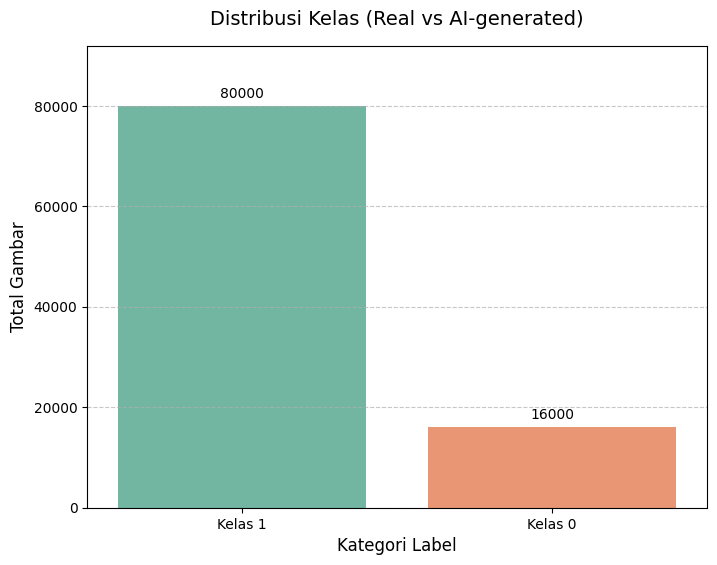

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- TASK 4: Analisis Distribusi Kelas Real dan AI-generated ---

# Mengambil data Label_A dari seluruh bagian dataset dan mengubahnya menjadi list
label_a_train = list(ds['train']['Label_A'])
label_a_val = list(ds['validation']['Label_A'])
label_a_test = list(ds['test']['Label_A'])

# Menggabungkan semuanya menjadi satu daftar panjang
semua_label_a = label_a_train + label_a_val + label_a_test

# Memasukkan data ke dalam DataFrame agar mudah dihitung dan divisualisasikan
df_kelas = pd.DataFrame({'Label_A': semua_label_a})

# Menghitung jumlah masing-masing kelas
distribusi_kelas = df_kelas['Label_A'].value_counts().reset_index()
distribusi_kelas.columns = ['Kode Label', 'Jumlah Gambar']

# Mengasumsikan 0 adalah Real dan 1 adalah AI-generated (atau sebaliknya, label akan tampil sesuai kodenya)
distribusi_kelas['Kategori'] = distribusi_kelas['Kode Label'].apply(lambda x: f"Kelas {x}")

print("=== TASK 4: DISTRIBUSI KELAS ===")
display(distribusi_kelas)

# Membuat grafik distribusi kelas
plt.figure(figsize=(8, 6))
ax = sns.barplot(data=distribusi_kelas, x='Kategori', y='Jumlah Gambar', palette='Set2')

# Menambahkan angka di atas batang grafik biar lebih informatif
for p in ax.patches:
    ax.annotate(format(p.get_height(), '.0f'),
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha = 'center', va = 'center',
                xytext = (0, 9),
                textcoords = 'offset points')

plt.title('Distribusi Kelas (Real vs AI-generated)', fontsize=14, pad=15)
plt.xlabel('Kategori Label', fontsize=12)
plt.ylabel('Total Gambar', fontsize=12)
plt.ylim(0, distribusi_kelas['Jumlah Gambar'].max() * 1.15) # Memberi ruang agar angka tidak terpotong
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

=== TASK 5: DISTRIBUSI BERDASARKAN GENERATOR AI ===


,Kode Generator,Jumlah Gambar,Kategori
0,0,16000,Generator 0
1,1,16000,Generator 1
2,2,16000,Generator 2
3,3,16000,Generator 3
4,4,16000,Generator 4
5,5,16000,Generator 5


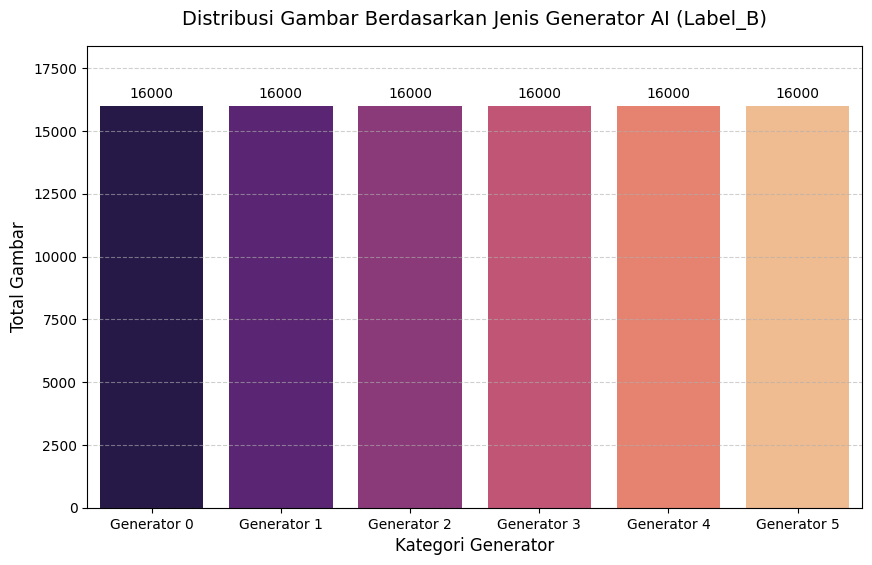

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- TASK 5: Analisis Distribusi Gambar Berdasarkan Generator AI ---

# Mengambil data Label_B (kategori generator) dari seluruh bagian dataset dan mengubahnya menjadi list
label_b_train = list(ds['train']['Label_B'])
label_b_val = list(ds['validation']['Label_B'])
label_b_test = list(ds['test']['Label_B'])

# Menggabungkan seluruh data menjadi satu
semua_label_b = label_b_train + label_b_val + label_b_test
df_generator = pd.DataFrame({'Label_B': semua_label_b})

# Menghitung jumlah gambar untuk setiap jenis generator AI
distribusi_gen = df_generator['Label_B'].value_counts().reset_index()
distribusi_gen.columns = ['Kode Generator', 'Jumlah Gambar']
distribusi_gen['Kategori'] = distribusi_gen['Kode Generator'].apply(lambda x: f"Generator {x}")

print("=== TASK 5: DISTRIBUSI BERDASARKAN GENERATOR AI ===")
display(distribusi_gen)

# Membuat visualisasi bar chart
plt.figure(figsize=(10, 6))

# Menggunakan parameter hue sesuai anjuran Seaborn terbaru untuk menghindari peringatan
ax = sns.barplot(
    data=distribusi_gen,
    x='Kategori',
    y='Jumlah Gambar',
    hue='Kategori',
    palette='magma',
    legend=False
)

# Menambahkan anotasi angka di atas setiap batang
for p in ax.patches:
    ax.annotate(format(p.get_height(), '.0f'),
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 9),
                textcoords='offset points',
                fontsize=10)

plt.title('Distribusi Gambar Berdasarkan Jenis Generator AI (Label_B)', fontsize=14, pad=15)
plt.xlabel('Kategori Generator', fontsize=12)
plt.ylabel('Total Gambar', fontsize=12)
plt.ylim(0, distribusi_gen['Jumlah Gambar'].max() * 1.15)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

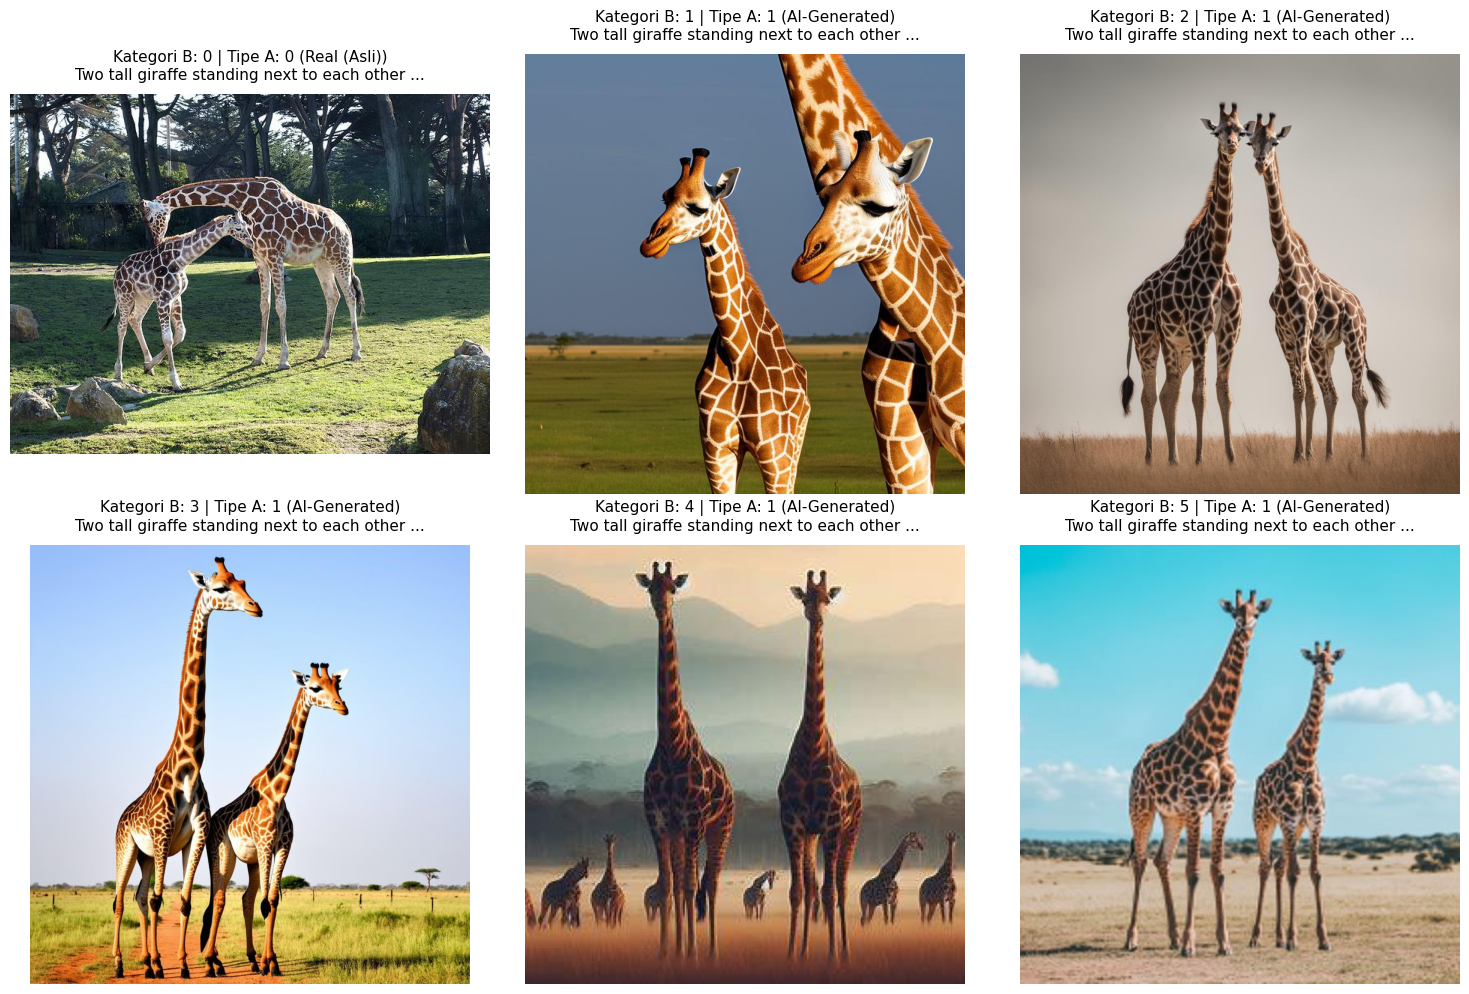

In [7]:
import matplotlib.pyplot as plt

# --- TASK 6: Menampilkan Contoh Gambar dari Setiap Kategori ---

# Menyiapkan wadah untuk menyimpan satu contoh gambar per kategori (Label_B)
contoh_gambar = {}
kategori_ditemukan = 0

# Melakukan perulangan pada split 'train' untuk mencari sampel
for sampel in ds['train']:
    label_b = sampel['Label_B']

    # Jika label ini belum ada di wadah kita, maka simpan
    if label_b not in contoh_gambar:
        contoh_gambar[label_b] = sampel
        kategori_ditemukan += 1

    # Hentikan pencarian jika ke-6 kategori (0 sampai 5) sudah terkumpul
    if kategori_ditemukan == 6:
        break

# Membuat area plot berupa grid dengan ukuran 2 baris dan 3 kolom
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

# Menampilkan gambar berurutan berdasarkan nomor Label_B (0 sampai 5)
for i, label in enumerate(sorted(contoh_gambar.keys())):
    sampel = contoh_gambar[label]
    gambar = sampel['Image']
    caption = sampel['Caption']
    label_a = sampel['Label_A']

    # Menampilkan objek gambar ke dalam grid
    axes[i].imshow(gambar)
    axes[i].axis('off') # Menyembunyikan garis tepi dan angka sumbu

    # Merangkai informasi untuk judul di atas setiap gambar
    tipe_gambar = "Real (Asli)" if label_a == 0 else "AI-Generated"

    # Memotong teks caption jika terlalu panjang agar layout tidak berantakan
    teks_caption = caption if len(caption) < 45 else caption[:45] + "..."
    judul = f"Kategori B: {label} | Tipe A: {label_a} ({tipe_gambar})\n{teks_caption}"

    axes[i].set_title(judul, fontsize=11, pad=10)

plt.tight_layout()
plt.show()

Menganalisis resolusi gambar pada split 'train' (proses ini mungkin butuh waktu beberapa detik)...

=== TASK 7: DISTRIBUSI RESOLUSI GAMBAR ===


,Ukuran (Lebar x Tinggi),Jumlah Gambar
0,1024x1024,14000
1,768x768,7000
2,436x436,6999
3,270x270,6970
4,640x480,1545
...,...,...
691,356x533,1
692,640x446,1
693,500x249,1
694,627x640,1


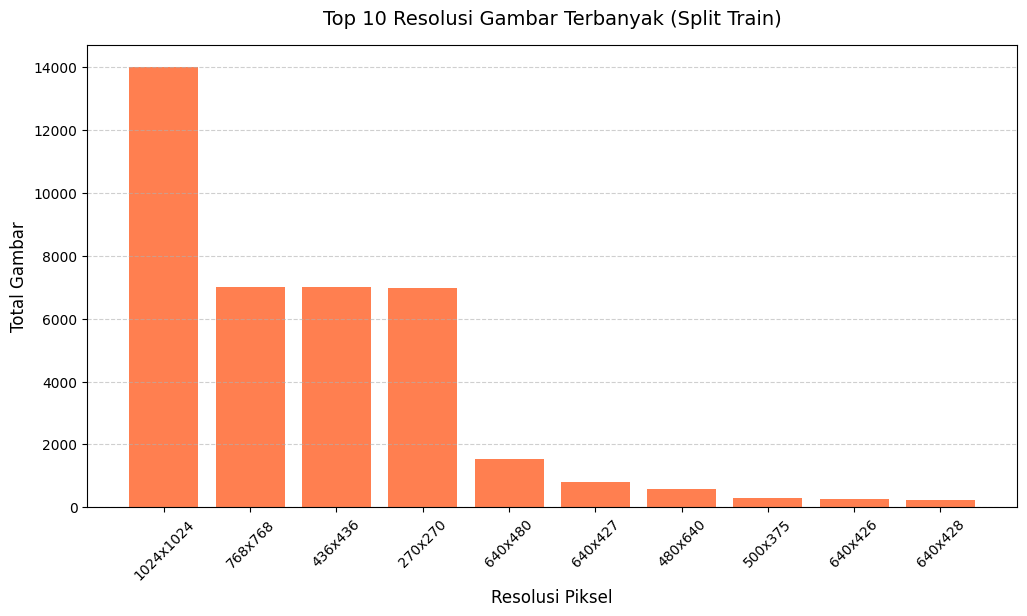

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

# --- TASK 7: Analisis Dimensi dan Resolusi Gambar ---
print("Menganalisis resolusi gambar pada split 'train' (proses ini mungkin butuh waktu beberapa detik)...")

# Mengumpulkan ukuran (lebar x tinggi) dari semua gambar di split train
list_resolusi = []
for sampel in ds['train']:
    ukuran = sampel['Image'].size # Mengembalikan tuple (width, height)
    list_resolusi.append(f"{ukuran[0]}x{ukuran[1]}")

# Memasukkan ke dalam DataFrame untuk dihitung
df_resolusi = pd.DataFrame({'Resolusi': list_resolusi})
distribusi_resolusi = df_resolusi['Resolusi'].value_counts().reset_index()
distribusi_resolusi.columns = ['Ukuran (Lebar x Tinggi)', 'Jumlah Gambar']

print("\n=== TASK 7: DISTRIBUSI RESOLUSI GAMBAR ===")
display(distribusi_resolusi)

# Menentukan jenis visualisasi berdasarkan banyaknya variasi resolusi
if len(distribusi_resolusi) <= 10:
    # Jika variasinya sedikit, kita gunakan Pie Chart agar proporsinya terlihat jelas
    plt.figure(figsize=(8, 8))
    plt.pie(
        distribusi_resolusi['Jumlah Gambar'],
        labels=distribusi_resolusi['Ukuran (Lebar x Tinggi)'],
        autopct='%1.1f%%',
        colors=plt.cm.Paired.colors,
        startangle=90
    )
    plt.title('Proporsi Resolusi Gambar (Split Train)', fontsize=14, pad=20)
    plt.show()
else:
    # Jika variasinya sangat banyak, kita tampilkan Top 10 terbanyak menggunakan Bar Chart
    plt.figure(figsize=(12, 6))
    top_10 = distribusi_resolusi.head(10)
    ax = plt.bar(top_10['Ukuran (Lebar x Tinggi)'], top_10['Jumlah Gambar'], color='coral')

    plt.title('Top 10 Resolusi Gambar Terbanyak (Split Train)', fontsize=14, pad=15)
    plt.xlabel('Resolusi Piksel', fontsize=12)
    plt.ylabel('Total Gambar', fontsize=12)
    plt.xticks(rotation=45)
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    plt.show()

In [9]:
import pandas as pd

# --- TASK 8: Audit Dataset (Missing Data, Gambar Rusak, & Duplikasi) ---
print("Memulai audit dataset pada split 'train'...")

null_counts = {'Caption': 0, 'Image': 0, 'Label_A': 0, 'Label_B': 0}
corrupt_images = 0
captions_list = []

for idx, sampel in enumerate(ds['train']):
    # 1. Cek Missing / Null Data
    for col in null_counts.keys():
        if sampel[col] is None:
            null_counts[col] += 1

    # 2. Cek Keutuhan Gambar
    img = sampel['Image']
    if img is None:
        corrupt_images += 1
    else:
        try:
            img.verify() # Verifikasi integritas objek gambar PIL
        except Exception:
            corrupt_images += 1

    # 3. Kumpulkan caption untuk analisis duplikasi
    if sampel['Caption']:
        captions_list.append(sampel['Caption'])

# Menghitung duplikasi teks caption
total_caption = len(captions_list)
unique_caption = len(set(captions_list))
duplicate_captions = total_caption - unique_caption

# Menyusun laporan audit ke dalam DataFrame
df_audit = pd.DataFrame({
    'Jenis Pemeriksaan': [
        'Missing / Null Caption',
        'Missing / Null Image',
        'Missing / Null Label_A',
        'Missing / Null Label_B',
        'Gambar Rusak (Corrupt Image)',
        'Duplikasi Teks Caption'
    ],
    'Jumlah Ditemukan': [
        null_counts['Caption'],
        null_counts['Image'],
        null_counts['Label_A'],
        null_counts['Label_B'],
        corrupt_images,
        duplicate_captions
    ],
    'Status Audit': [
        'Aman' if null_counts['Caption'] == 0 else 'Ada Null',
        'Aman' if null_counts['Image'] == 0 else 'Ada Null',
        'Aman' if null_counts['Label_A'] == 0 else 'Ada Null',
        'Aman' if null_counts['Label_B'] == 0 else 'Ada Null',
        'Aman' if corrupt_images == 0 else 'Ada Rusak',
        'Unik Semua' if duplicate_captions == 0 else 'Ada Duplikat'
    ]
})

print("\n=== TASK 8: LAPORAN AUDIT DATASET (SPLIT TRAIN) ===")
display(df_audit)

Memulai audit dataset pada split 'train'...

=== TASK 8: LAPORAN AUDIT DATASET (SPLIT TRAIN) ===


,Jenis Pemeriksaan,Jumlah Ditemukan,Status Audit
0,Missing / Null Caption,0,Aman
1,Missing / Null Image,0,Aman
2,Missing / Null Label_A,0,Aman
3,Missing / Null Label_B,0,Aman
4,Gambar Rusak (Corrupt Image),0,Aman
5,Duplikasi Teks Caption,35052,Ada Duplikat


In [10]:
import pandas as pd

# --- TASK 9: Analisis Hubungan Gambar Berdasarkan Teks Caption ---
print("Menganalisis keterkaitan antara Teks Caption dan Kategori Gambar...")

# Mengambil data Caption dan Label_B dari split train
captions = ds['train']['Caption']
label_b_list = ds['train']['Label_B']

df_cap = pd.DataFrame({'Caption': captions, 'Label_B': label_b_list})

# Mengelompokkan data berdasarkan teks Caption
relasi_caption = df_cap.groupby('Caption').agg(
    total_gambar=('Label_B', 'count'),
    variasi_generator=('Label_B', 'nunique')
).reset_index()

print("\n=== TASK 9: FREKUENSI GAMBAR PER CAPTION ===")
distribusi_relasi = relasi_caption['total_gambar'].value_counts().reset_index()
distribusi_relasi.columns = ['Jumlah Gambar per Caption', 'Frekuensi Caption']
display(distribusi_relasi)

# Memeriksa berapa banyak caption yang memiliki pasangan 6 variasi lengkap (0 s/d 5)
caption_lengkap = (relasi_caption['variasi_generator'] == 6).sum()
total_unique_caption = len(relasi_caption)
persentase_lengkap = (caption_lengkap / total_unique_caption) * 100

print(f"\n=== INSIGHT HUBUNGAN CAPTION ===")
print(f"Total Unique Caption          : {total_unique_caption} teks")
print(f"Caption dengan 6 Variasi (0-5): {caption_lengkap} ({persentase_lengkap:.2f}%)")

Menganalisis keterkaitan antara Teks Caption dan Kategori Gambar...

=== TASK 9: FREKUENSI GAMBAR PER CAPTION ===


,Jumlah Gambar per Caption,Frekuensi Caption
0,6,6908
1,12,34
2,18,3
3,36,1
4,30,1
5,24,1



=== INSIGHT HUBUNGAN CAPTION ===
Total Unique Caption          : 6948 teks
Caption dengan 6 Variasi (0-5): 6948 (100.00%)


# **Ringkasan Insight EDA dan Rekomendasi Preprocessing**


---



**1.   Kondisi Kelas yang Imbalanced**


Dataset ini memiliki ketidakseimbangan kelas yang cukup ekstrem pada klasifikasi utamanya (Label A). Gambar buatan AI (Kelas 1) mendominasi dengan jumlah 80.000 sampel, sementara gambar asli (Kelas 0) hanya berjumlah 16.000 sampel. Rasio 1:5 ini perlu mendapat perhatian khusus agar model yang nanti dibangun tidak bias dan hanya memprediksi mayoritas kelas AI.


**2.   Struktur Data Berpasangan (Paired Dataset)**

Analisis hubungan teks caption dengan kategori gambar (Label B) membuktikan bahwa dataset ini disusun secara paralel. Sebanyak 100% teks deskripsi memiliki representasi visual yang lengkap mulai dari generator tipe 0 hingga tipe 5. Struktur berpasangan ini memastikan model nantinya benar-benar belajar mengenali artefak visual buatan AI, bukan malah menghafal konteks atau objek dari adegan tertentu.

**3.   Kebersihan dan Keutuhan Data**


Dataset berada dalam kondisi yang sangat bersih. Hasil audit menunjukkan tidak ada nilai kosong (missing data) pada kolom gambar, label, maupun caption. Seluruh objek file gambar juga utuh dan tidak ada file korup yang dapat menggagalkan proses training di tengah jalan.


**4.   Variasi Dimensi Gambar yang Masif**


  Resolusi gambar sangat bervariasi hingga mencapai 686 ukuran yang berbeda. Walaupun mayoritas berada di ukuran 1024x1024 dan 768x768, variasi yang terlalu banyak ini mewajibkan adanya penyeragaman bentuk tensor sebelum masuk ke arsitektur jaringan saraf tiruan.


---



**Rekomendasi Strategi Preprocessing**




*   Standardisasi Resolusi (Resizing):

      Semua gambar wajib di-resize ke dimensi persegi yang seragam untuk meminimalkan beban komputasi. Mengingat pendekatan yang lebih ringan dan efisien sering kali lebih optimal untuk dieksekusi, ukuran seperti 224x224 piksel sangat direkomendasikan. Ukuran ini merupakan standar industri yang langsung kompatibel dengan sebagian besar arsitektur model prebuilt ringan untuk ekstraksi fitur.

*   Penanganan Imbalance Data:

      Ketimpangan jumlah data asli dan AI tidak bisa dibiarkan begitu saja. Pendekatan class weighting pada fungsi loss bisa diterapkan saat pelatihan agar model memberikan bobot penalti yang lebih besar saat salah menebak kelas minoritas. Alternatif lainnya adalah melakukan augmentasi data secara moderat khusus untuk gambar-gambar pada Kelas 0.

*   Normalisasi Tensor:

      Skala nilai piksel mentah (0-255) harus diubah menggunakan normalisasi rentang 0 hingga 1. Jika nantinya menggunakan transfer learning, standardisasi lanjutan menggunakan nilai mean dan standard deviation bawaan arsitektur juga perlu diterapkan untuk mempercepat konvergensi model.











In [14]:
import os
from PIL import Image
import io
from tqdm import tqdm

# Karena dataset sudah dimuat di cell sebelumnya ke dalam variabel 'ds',
# kita bisa langsung menggunakannya tanpa harus memuat ulang menggunakan load_from_disk.
dataset = ds

print(f"Struktur Dataset yang digunakan: {dataset}")

# Fungsi untuk memeriksa dan membersihkan data gambar di dalam dataset Hugging Face
def validate_and_clean_hf_dataset(ds):
    corrupted_indices = []
    total_checked = 0

    # Menelusuri split yang ada (misal: train, test, validation)
    for split_name in ds.keys():
        print(f"\nMemeriksa split: {split_name} (Total: {len(ds[split_name])} data)")

        # Batasi pemeriksaan atau periksa semua sesuai kebutuhan
        for idx in tqdm(range(len(ds[split_name])), desc=f"Validasi {split_name}"):
            total_checked += 1
            try:
                # Mengambil sampel data gambar (kolom 'Image' menggunakan huruf kapital sesuai struktur dataset)
                sample = ds[split_name][idx]

                # Cek apakah kolom gambar ada
                img_data = sample.get('Image')
                if img_data is None:
                    corrupted_indices.append((split_name, idx))
                    continue

                # Verifikasi integritas objek gambar PIL
                if isinstance(img_data, Image.Image):
                    img_data.verify()
                elif isinstance(img_data, bytes):
                    img = Image.open(io.BytesIO(img_data))
                    img.verify()

            except Exception as e:
                corrupted_indices.append((split_name, idx))

    print("\n--- LAPORAN DATA CLEANING (HUGGING FACE DATASET) ---")
    print(f"Total data yang diperiksa : {total_checked}")
    print(f"Total data rusak/invalid  : {len(corrupted_indices)}")
    if len(corrupted_indices) > 0:
        print(f"Indeks data yang rusak: {corrupted_indices}")
    else:
        print("Semua data gambar dalam kondisi utuh dan valid!")

# Jalankan validasi menggunakan dataset yang sudah ada di memory (ds)
validate_and_clean_hf_dataset(dataset)

Struktur Dataset yang digunakan: DatasetDict({
    validation: Dataset({
        features: ['Caption', 'Image', 'Label_A', 'Label_B'],
        num_rows: 9000
    })
    train: Dataset({
        features: ['Caption', 'Image', 'Label_A', 'Label_B'],
        num_rows: 42000
    })
    test: Dataset({
        features: ['Caption', 'Image', 'Label_A', 'Label_B'],
        num_rows: 45000
    })
})

Memeriksa split: validation (Total: 9000 data)


Validasi validation: 100%|██████████| 9000/9000 [00:47<00:00, 191.08it/s]



Memeriksa split: train (Total: 42000 data)


Validasi train: 100%|██████████| 42000/42000 [03:09<00:00, 221.33it/s]



Memeriksa split: test (Total: 45000 data)


Validasi test: 100%|██████████| 45000/45000 [03:25<00:00, 218.78it/s]


--- LAPORAN DATA CLEANING (HUGGING FACE DATASET) ---
Total data yang diperiksa : 96000
Total data rusak/invalid  : 0
Semua data gambar dalam kondisi utuh dan valid!


In [15]:
import pandas as pd
from collections import Counter

def analyze_class_distribution(ds):
    for split_name in ds.keys():
        print(f"\n--- Distribusi Kelas pada Split: {split_name} ---")

        # Mengambil label dari kolom Label_A dan Label_B
        labels_a = ds[split_name]['Label_A']
        labels_b = ds[split_name]['Label_B']

        counts_a = Counter(labels_a)
        counts_b = Counter(labels_b)

        print("Label_A (Real vs AI):", counts_a)
        print("Label_B (Generator):", counts_b)

# Jalankan analisis distribusi
analyze_class_distribution(dataset)


--- Distribusi Kelas pada Split: validation ---
Label_A (Real vs AI): Counter({1: 7500, 0: 1500})
Label_B (Generator): Counter({3: 1500, 0: 1500, 1: 1500, 4: 1500, 2: 1500, 5: 1500})

--- Distribusi Kelas pada Split: train ---
Label_A (Real vs AI): Counter({1: 35000, 0: 7000})
Label_B (Generator): Counter({0: 7000, 1: 7000, 2: 7000, 3: 7000, 4: 7000, 5: 7000})

--- Distribusi Kelas pada Split: test ---
Label_A (Real vs AI): Counter({1: 37500, 0: 7500})
Label_B (Generator): Counter({5: 7500, 0: 7500, 1: 7500, 2: 7500, 3: 7500, 4: 7500})


In [16]:
# Menyiapkan dan menetapkan pembagian dataset (splitting) dari DatasetDict yang sudah ada
train_dataset = dataset['train']
val_dataset = dataset['validation']
test_dataset = dataset['test']

print("--- INFORMASI PEMBAGIAN DATASET (TASK 3) ---")
print(f"Jumlah data Training   : {len(train_dataset)} sampel")
print(f"Jumlah data Validation : {len(val_dataset)} sampel")
print(f"Jumlah data Testing    : {len(test_dataset)} sampel")
print("\nPembagian dataset berhasil disiapkan dan siap digunakan ke tahap berikutnya!")

--- INFORMASI PEMBAGIAN DATASET (TASK 3) ---
Jumlah data Training   : 42000 sampel
Jumlah data Validation : 9000 sampel
Jumlah data Testing    : 45000 sampel

Pembagian dataset berhasil disiapkan dan siap digunakan ke tahap berikutnya!


In [17]:
# Memeriksa Data Leakage berdasarkan irisan Caption antar Split
train_captions = set(train_dataset['Caption'])
val_captions = set(val_dataset['Caption'])
test_captions = set(test_dataset['Caption'])

# Mencari irisan (intersection) antar split
leak_train_val = train_captions.intersection(val_captions)
leak_train_test = train_captions.intersection(test_captions)
leak_val_test = val_captions.intersection(test_captions)

print("--- LAPORAN PEMERIKSAAN DATA LEAKAGE ---")
print(f"Jumlah caption tumpang tindih antara Train & Val : {len(leak_train_val)}")
print(f"Jumlah caption tumpang tindih antara Train & Test: {len(leak_train_test)}")
print(f"Jumlah caption tumpang tindih antara Val & Test  : {len(leak_val_test)}")

if len(leak_train_val) == 0 and len(leak_train_test) == 0 and len(leak_val_test) == 0:
    print("\nAMAN! Tidak ditemukan adanya data leakage (kebocoran data) antar split.")
else:
    print("\nPERHATIAN: Ditemukan adanya tumpang tindih caption antar split.")

--- LAPORAN PEMERIKSAAN DATA LEAKAGE ---
Jumlah caption tumpang tindih antara Train & Val : 25
Jumlah caption tumpang tindih antara Train & Test: 31
Jumlah caption tumpang tindih antara Val & Test  : 7

PERHATIAN: Ditemukan adanya tumpang tindih caption antar split.


In [18]:
from torchvision import transforms

# Menentukan ukuran target resizing (misalnya 224x224 piksel untuk standar CNN/ViT)
IMG_SIZE = 224

# Membuat fungsi transformasi untuk resizing dan konversi ke tensor
transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
])

print(f"--- INFORMASI TASK 5 (IMAGE RESIZING) ---")
print(f"Target ukuran gambar berhasil diatur ke : {IMG_SIZE}x{IMG_SIZE} piksel")
print("Transformasi PyTorch (Resize & ToTensor) siap diterapkan pada dataset!")

--- INFORMASI TASK 5 (IMAGE RESIZING) ---
Target ukuran gambar berhasil diatur ke : 224x224 piksel
Transformasi PyTorch (Resize & ToTensor) siap diterapkan pada dataset!


In [19]:
from torchvision import transforms

# Memperbarui pipeline transformasi dengan menambahkan fungsi konversi ke RGB (3 channel)
transform = transforms.Compose([
    transforms.Lambda(lambda img: img.convert('RGB')), # Memastikan format selalu RGB
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

print("--- INFORMASI TASK 6 (FORMAT RGB) ---")
print("Transformasi berhasil diperbarui dengan penambahan filter konversi RGB otomatis.")
print("Semua gambar kini dijamin memiliki 3 channel warna (RGB) saat dimuat!")

--- INFORMASI TASK 6 (FORMAT RGB) ---
Transformasi berhasil diperbarui dengan penambahan filter konversi RGB otomatis.
Semua gambar kini dijamin memiliki 3 channel warna (RGB) saat dimuat!


In [20]:
from torchvision import transforms

# 1. Menentukan konfigurasi lengkap preprocessing (Konversi RGB -> Resize -> ToTensor -> Normalisasi)
# Menggunakan mean dan std standar ImageNet [0.485, 0.456, 0.406] dan [0.229, 0.224, 0.225]
complete_transform = transforms.Compose([
    transforms.Lambda(lambda img: img.convert('RGB')),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 2. Fungsi untuk menerapkan transformasi ke sampel dataset Hugging Face
def preprocess_function(examples):
    # Menerapkan transformasi pada setiap gambar di batch
    examples['pixel_values'] = [complete_transform(img) for img in examples['Image']]
    return examples

print("--- INFORMASI TASK 7 (KONFIGURASI PREPROCESSING) ---")
print("Pipeline preprocessing lengkap (Resize, RGB, ToTensor, dan Normalisasi ImageNet) telah berhasil dikonfigurasi!")
print("Fungsi 'preprocess_function' siap digunakan untuk mentransformasi dataset.")

--- INFORMASI TASK 7 (KONFIGURASI PREPROCESSING) ---
Pipeline preprocessing lengkap (Resize, RGB, ToTensor, dan Normalisasi ImageNet) telah berhasil dikonfigurasi!
Fungsi 'preprocess_function' siap digunakan untuk mentransformasi dataset.


In [21]:
from torchvision import transforms

# 1. Pipeline khusus Training (dengan Augmentasi)
train_transform = transforms.Compose([
    transforms.Lambda(lambda img: img.convert('RGB')),
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5), # Membalikkan gambar secara horizontal dengan probabilitas 50%
    transforms.RandomRotation(degrees=15),  # Memutar gambar secara acak hingga 15 derajat
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 2. Pipeline standar untuk Validation dan Test (Tanpa Augmentasi)
eval_transform = transforms.Compose([
    transforms.Lambda(lambda img: img.convert('RGB')),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

print("--- INFORMASI TASK 8 (DATA AUGMENTATION) ---")
print("Pipeline 'train_transform' (dengan Random Flip & Rotation) berhasil disiapkan.")
print("Pipeline 'eval_transform' standar untuk validasi/testing juga siap digunakan!")

--- INFORMASI TASK 8 (DATA AUGMENTATION) ---
Pipeline 'train_transform' (dengan Random Flip & Rotation) berhasil disiapkan.
Pipeline 'eval_transform' standar untuk validasi/testing juga siap digunakan!


In [22]:
# Membuat kamus label mapping untuk Label_A (Real vs AI) dan Label_B (Generator)
label_a_mapping = {
    0: "Real",
    1: "AI-Generated"
}

# Berdasarkan EDA sebelumnya, Label_B memiliki 6 jenis generator (0 sampai 5)
label_b_mapping = {
    0: "Generator 0",
    1: "Generator 1",
    2: "Generator 2",
    3: "Generator 3",
    4: "Generator 4",
    5: "Generator 5"
}

print("--- INFORMASI TASK 9 (LABEL MAPPING) ---")
print(f"Label Mapping A (Real vs AI) : {label_a_mapping}")
print(f"Label Mapping B (Generator)  : {label_b_mapping}")
print("\nLabel mapping berhasil dibuat dan siap digunakan untuk proses klasifikasi!")

--- INFORMASI TASK 9 (LABEL MAPPING) ---
Label Mapping A (Real vs AI) : {0: 'Real', 1: 'AI-Generated'}
Label Mapping B (Generator)  : {0: 'Generator 0', 1: 'Generator 1', 2: 'Generator 2', 3: 'Generator 3', 4: 'Generator 4', 5: 'Generator 5'}

Label mapping berhasil dibuat dan siap digunakan untuk proses klasifikasi!


In [24]:
import json
import os

# Menyiapkan data manifest dataset
dataset_manifest = {
    "project_name": "Defactify Image Dataset Preprocessing",
    "splits": {
        "train": len(train_dataset),
        "validation": len(val_dataset),
        "test": len(test_dataset)
    },
    "label_mapping": {
        "Label_A": label_a_mapping,
        "Label_B": label_b_mapping
    },
    "image_resolution": [224, 224],
    "description": "Manifest dataset yang divalidasi dan disiapkan bersama Michael dan Bagas untuk kolaborasi pemodelan."
}

# Tentukan lokasi penyimpanan di Google Drive
manifest_dir = '/content/drive/MyDrive/dataset_huggingface'
os.makedirs(manifest_dir, exist_ok=True)
manifest_path = os.path.join(manifest_dir, 'dataset_manifest.json')

# Menyimpan ke file JSON
with open(manifest_path, 'w', encoding='utf-8') as f:
    json.dump(dataset_manifest, f, indent=4)

print("--- INFORMASI TASK 10 (MANIFEST DATASET) ---")
print(f"File manifest berhasil disimpan di: {manifest_path}")

--- INFORMASI TASK 10 (MANIFEST DATASET) ---
File manifest berhasil disimpan di: /content/drive/MyDrive/dataset_huggingface/dataset_manifest.json
